In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm 
import scipy.stats as stats
import seaborn as sns

In [58]:
base = pd.read_csv('./train.csv')
train = base.sample(frac = 0.8, random_state = 42)
test = base.drop(train.index)

In [59]:
train =  train.select_dtypes('number')
train.head()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
892,893,20,70.0,8414,6,8,1963,2003,0.0,663,...,192,0,0,0,0,0,0,2,2006,154500
1105,1106,60,98.0,12256,8,5,1994,1995,362.0,1032,...,186,32,0,0,0,0,0,4,2010,325000
413,414,30,56.0,8960,5,6,1927,1950,0.0,0,...,0,0,130,0,0,0,0,3,2010,115000
522,523,50,50.0,5000,6,7,1947,1950,0.0,399,...,0,24,36,0,0,0,0,10,2006,159000
1036,1037,20,89.0,12898,9,5,2007,2008,70.0,1022,...,228,0,0,0,0,0,0,9,2009,315500


In [60]:

colunms = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'SalePrice', 'YearBuilt', 'OverallCond', 'YearRemodAdd']
train = train[colunms]
train = train[train['GrLivArea'] < 2700]
train = train[(train['TotalBsmtSF'] > 0) & (train['TotalBsmtSF'] < 2300)]
train = train[(train['SalePrice'] > 100000) & (train['SalePrice'] < 350000)]
train = train[train['YearRemodAdd'] > 1950]
train = train[(train['OverallQual'] > 5.5) & (train['OverallQual'] < 9)]
train = train[train['GarageCars'] < 4]
train = train[(train['YearBuilt'] > 1920)]
train.head()

,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,SalePrice,YearBuilt,OverallCond,YearRemodAdd
892,6,1068,1,1059,154500,1963,8,2003
1105,8,2622,2,1463,325000,1994,5,1995
218,7,1954,2,798,311500,1939,9,2006
1160,6,1456,2,855,146000,1978,5,1978
567,7,1535,2,1517,214000,2004,5,2004


<Axes: >

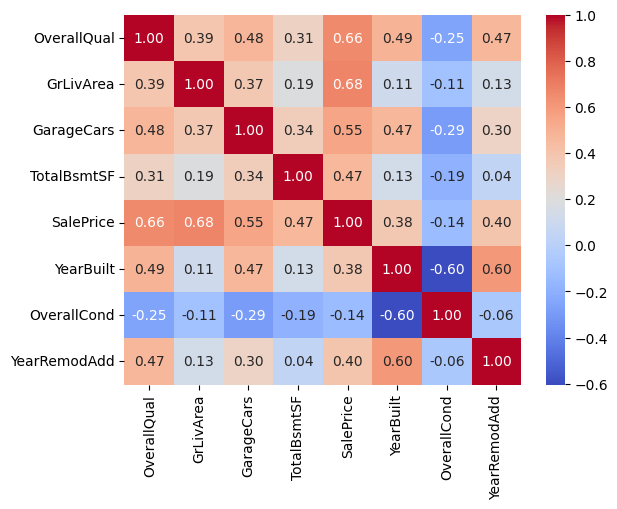

In [61]:
corr = train.corr()

sns.heatmap(corr, cmap = 'coolwarm', annot = True, fmt = '.2f')

<function matplotlib.pyplot.show(close=None, block=None)>

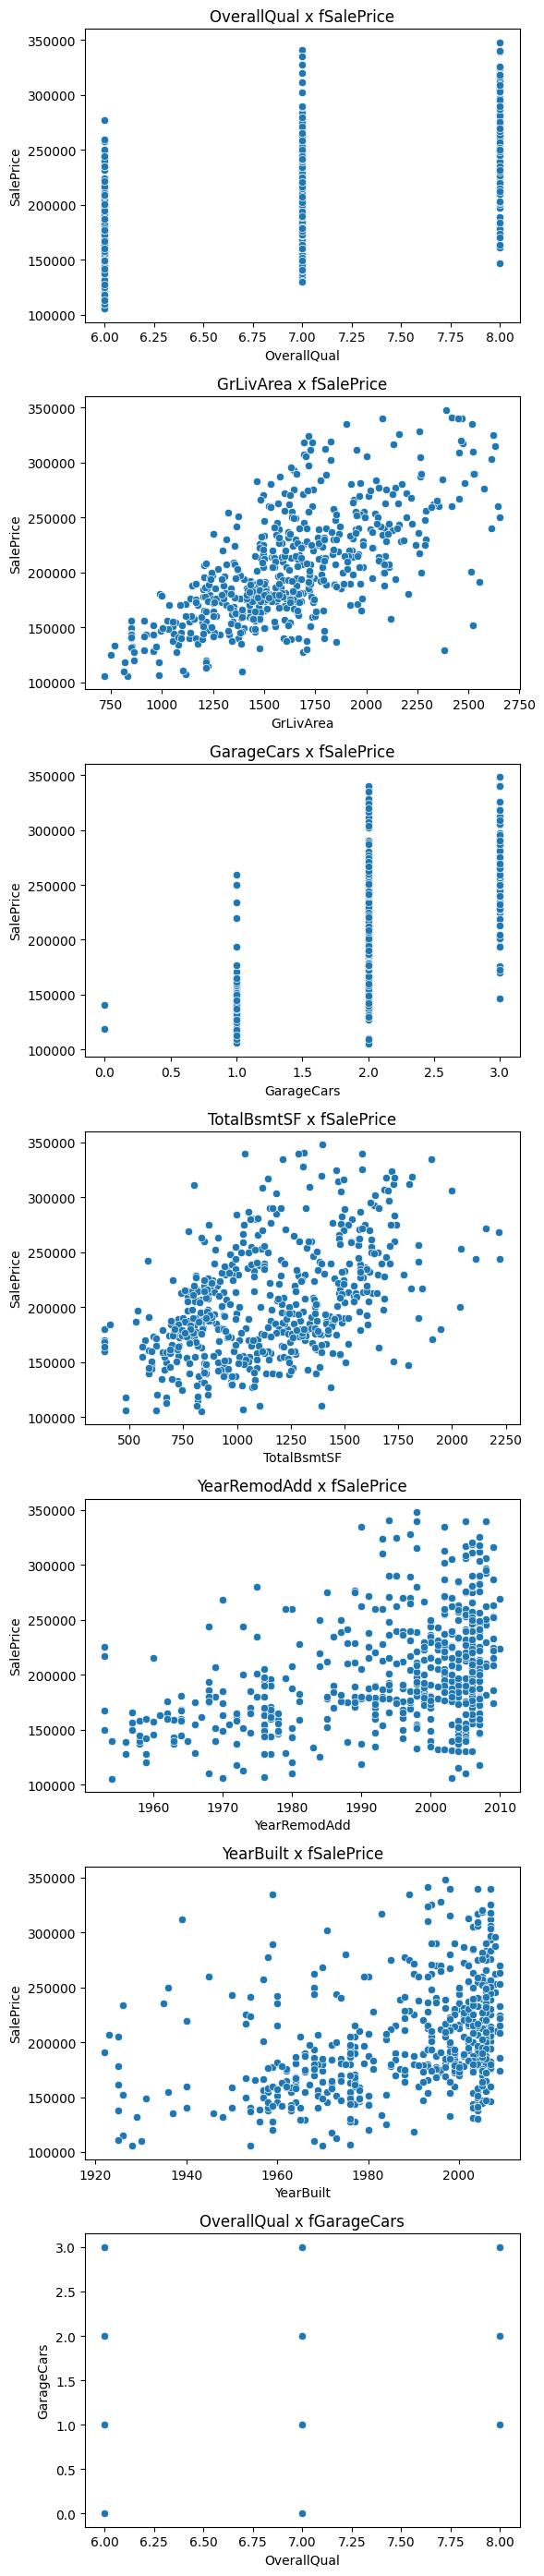

In [62]:
columns_pairs = [('OverallQual', 'SalePrice' ), ('GrLivArea', 'SalePrice'), ( 'GarageCars', 'SalePrice'),  ( 'TotalBsmtSF', 'SalePrice' ), ('YearRemodAdd', 'SalePrice'), ( 'YearBuilt', 'SalePrice'), ('OverallQual', 'GarageCars')]

n_plots = len(columns_pairs)

fig, axes = plt.subplots(nrows = n_plots, ncols = 1, figsize = (6, 4 * n_plots))

for i, pair in enumerate(columns_pairs):
    x_col, y_col = pair
    sns.scatterplot(x = x_col, y = y_col, data = train, ax = axes[i])

    axes[i].set_title(f'{x_col} x f{y_col}')

plt.tight_layout()
plt.show

In [63]:
model = sm.ols(formula = 'np.log(SalePrice) ~ GrLivArea + OverallQual + TotalBsmtSF  + YearBuilt + OverallCond', data = train)

model = model.fit()
model.summary()

# without SalePrice log (good):
#     aic : 3.453e+04;
#     bic : 3.456e+04;
#     r² : 0.803;
#     adj. r² : 0.802.

# with  SalePrice log
#     aic : -1092.;
#     bic : -1065.;
#     r² : 0.825;
#     adj. r² : 0.824.



<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      np.log(SalePrice)   R-squared:                       0.748
Model:                            OLS   Adj. R-squared:                  0.746
Method:                 Least Squares   F-statistic:                     336.6
Date:                Thu, 08 Oct 2026   Prob (F-statistic):          4.50e-167
Time:                        17:26:34   Log-Likelihood:                 393.05
No. Observations:                 573   AIC:                            -774.1
Df Residuals:                     567   BIC:                            -748.0
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       3.2540      0.714      4.560      0.000       1.853       4.656
GrLivArea       0.0003   1.45e-05     22.138      0.000       0.000       0.000
OverallQual     0.0876      0.009      9.945      0.000       0.070       0.105
TotalBsmtSF     0.0002   1.57e-05     12.528      0.000       0.000       0.000
YearBuilt       0.0037      0.000     10.270      0.000       0.003       0.004
OverallCond     0.0529      0.007      7.591      0.000       0.039       0.067
==============================================================================
Omnibus:                       57.758   Durbin-Watson:                   1.856
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              159.960
Skew:                          -0.492   Prob(JB):                     1.84e-35
Kurtosis:                       5.394   Cond. No.                     3.93e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.93e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

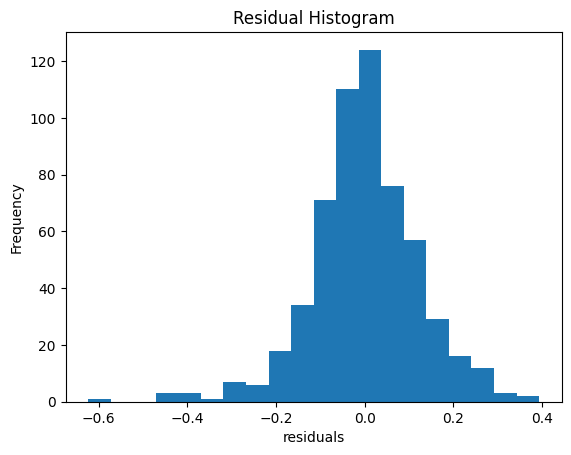

1324


In [64]:
residual = model.resid
plt.hist(residual, bins = 20)
plt.xlabel('residuals')
plt.ylabel('Frequency')
plt.title('Residual Histogram')
plt.show()
print(residual.idxmin())

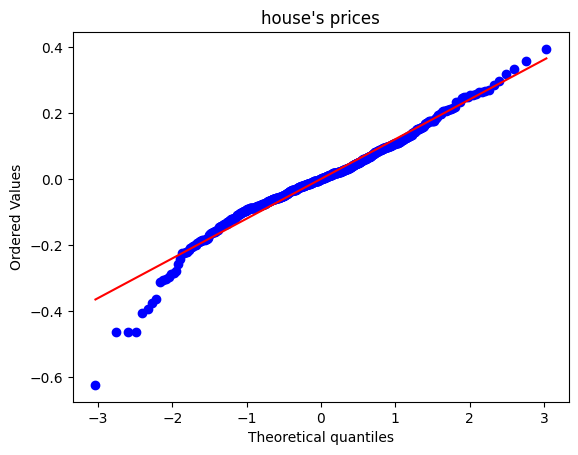

In [65]:
stats.probplot(residual, dist = 'norm', plot = plt)
plt.title("house's prices")
plt.show()

In [66]:
shapiro_test = stats.shapiro(residual)
print (f'Shapiro-Wilk Test: W = {shapiro_test[0]}, p-value = {shapiro_test[1]}')

Shapiro-Wilk Test: W = 0.9688593928019963, p-value = 1.1257582882596944e-09


In [67]:
prediction = np.exp(model.predict(test))
real = test['SalePrice']

error_mediun = np.mean(np.abs(real - prediction))
error_percent = np.mean(np.abs(real - prediction) / real) * 100
rmse_log = np.sqrt(np.mean((np.log(prediction) - np.log(real)) ** 2))
r2 = 1 - np.sum((real - prediction) **2) / np.sum((real - real.mean()) **2)

print(f'Erro médio: {error_mediun}')
print(f'Erro médio percentual: {error_percent:.2f}%')
print(f'RMSE (log): {rmse_log:.4f}%')
print(f'R² no teste: {r2:.3f}')

comparation = pd.DataFrame({'Real': real, 'Prediction': prediction.round(0)})
comparation['Diferença'] = comparation['Real'] - comparation['Prediction']
comparation.head(10)

Erro médio: 17899.879169468884
Erro médio percentual: 10.02%
RMSE (log): 0.1357%
R² no teste: 0.866


,Real,Prediction,Diferença
1,181500,183399.0,-1899.0
8,129900,160613.0,-30713.0
13,279500,215078.0,64422.0
14,157000,146877.0,10123.0
20,325300,290760.0,34540.0
21,139400,134990.0,4410.0
26,134800,120538.0,14262.0
34,277500,264318.0,13182.0
37,153000,141967.0,11033.0
40,160000,148181.0,11819.0
